# 02 · Data ingestion, the data contract and point-in-time state

**Who this is for:** anyone plugging their own data into `fmflow`. It covers:
- the two-table contract and the errors it raises;
- how to map a vendor feed;
- the cleaning audit trail;
- the point-in-time analyst snapshot that every signal is built on;
- the causality audit for your configuration.

The 30-stock open dataset shipped in `data/open/` (never-seen period 2024–26; 20 of its names were never used in development) is used throughout.

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")

30 stocks, 899 sessions, 2,363 accepted ratings


## 1. The contract

Two long tables:
- `prices`: `date, stock, price`;
- `ratings`: `date, estimate_value, stock, analyst`.

`load_prices` and `load_ratings` validate the structure **before** anything is computed. They raise a `DataContractError` with an actionable message instead of failing deep inside the pipeline.

In [3]:
from fmflow.data.schema import DataContractError, validate_prices, validate_ratings
raw_p = pd.read_csv(ROOT / "data/open/MarketData_Normalized.csv")
raw_r = pd.read_csv(ROOT / "data/open/Ratings_Normalized.csv", dtype=str)
print(raw_p.head(3), "\n", raw_r.head(3))

# The most common ingestion error: targets in currency, prices normalised (or the reverse)
bad = raw_r.assign(estimate_value=pd.to_numeric(raw_r["estimate_value"]) * 150)
try:
    validate_ratings(bad, raw_p)
except DataContractError as e:
    print("DataContractError:", e)
try:
    validate_prices(raw_p.rename(columns={"price": "close"}))
except DataContractError as e:
    print("DataContractError:", e)

         date     stock  price
0  2023-01-04   stock_1  1.000
1  2023-01-04  stock_10  1.000
2  2023-01-04  stock_11  1.000 
          date estimate_value     stock     analyst
0  2023-01-04         1.6619   stock_1  analyst_46
1  2023-01-04         1.3849   stock_1  analyst_49
2  2023-01-23         1.1654  stock_20   analyst_2
DataContractError: ratings: median target/price = 179; targets must be expressed on the same scale as prices (e.g. both normalised by the first price)
DataContractError: prices: missing columns ['price']; expected ('date', 'stock', 'price')


## 2. Mapping a vendor feed

The example below fakes an I/B/E/S-style detail file to show the mapping:
- `anndats` is the publication date;
- `value` is the target;
- `amaskcd` is the analyst code.

The only real decision is to put **prices and targets on the same adjustment basis**. See `DATA.md` §4 for FactSet, Bloomberg and Refinitiv.

In [4]:
vendor = raw_r.rename(columns={"date": "anndats", "estimate_value": "value", "stock": "ticker", "analyst": "amaskcd"})
mapped = vendor.rename(columns={"anndats": "date", "value": "estimate_value", "ticker": "stock", "amaskcd": "analyst"})
validate_ratings(mapped, raw_p)
print("mapped feed satisfies the contract:", list(mapped.columns))

mapped feed satisfies the contract: ['date', 'estimate_value', 'stock', 'analyst']


## 3. The cleaning audit trail

Every rule writes a row, so you know exactly what was dropped and why. The synthetic generator can inject the usual vendor errors: fat-finger targets, missing analyst ids, text values and duplicates.

In [5]:
display(out.audit)
from fmflow.synthetic import SyntheticConfig, generate
p_err, r_err = generate(SyntheticConfig(n_sessions=600, inject_errors=True, seed=3))
o_err = run_strategy(p_err, r_err, StrategyConfig.fmf_n().with_(allocator="EW"))
display(o_err.audit[o_err.audit["n_rows"] > 0])

,dataset,check,finding,n_rows,decision
0,prices,clean,Unparseable dates dropped,0,drop
1,prices,clean,Missing stock identifier,0,drop
2,prices,clean,Non-positive prices set to NaN,0,set NaN
3,prices,clean,"Duplicate (date, stock) keys",0,keep last
4,prices,clean,Non-sessions removed (coverage < 50% of active...,0,drop date
5,prices,clean,Stale rows (all prices unchanged),0,drop date
6,prices,clean,Isolated gaps forward-filled (limit 5),0,ffill
7,ratings,R1,Unparseable / non-positive target,0,drop
8,ratings,R1,Unparseable publication date,0,drop
9,ratings,R2,Missing analyst identifier,0,drop


,dataset,check,finding,n_rows,decision
7,ratings,R1,Unparseable / non-positive target,3,drop
9,ratings,R2,Missing analyst identifier,3,drop
11,ratings,clean,"Duplicate (date, stock, analyst)",14,keep last
12,ratings,R6,Published after the last session (not yet usable),5,drop
14,ratings,R3,"TP/P outside (0.2, 5.0)",3,drop
15,ratings,R4,Target change inconsistent with price change (...,3,drop


## 4. The point-in-time snapshot

- A rating published on day *p* is usable from the **next session**. This is its knowledge date.
- An analyst's target stays active until it is replaced or expires after 252 sessions.
- Each rating is classified as an initiation, a reiteration, or a fresh up or down revision.
- Information events are days with five or more ratings on one stock.

knowledge date strictly after publication: True
calendar days from publication to usability: {'min': 1.0, '50%': 1.0, 'max': 4.0}
{'up': 0.348, 'reiteration': 0.309, 'initiation': 0.198, 'down': 0.145}


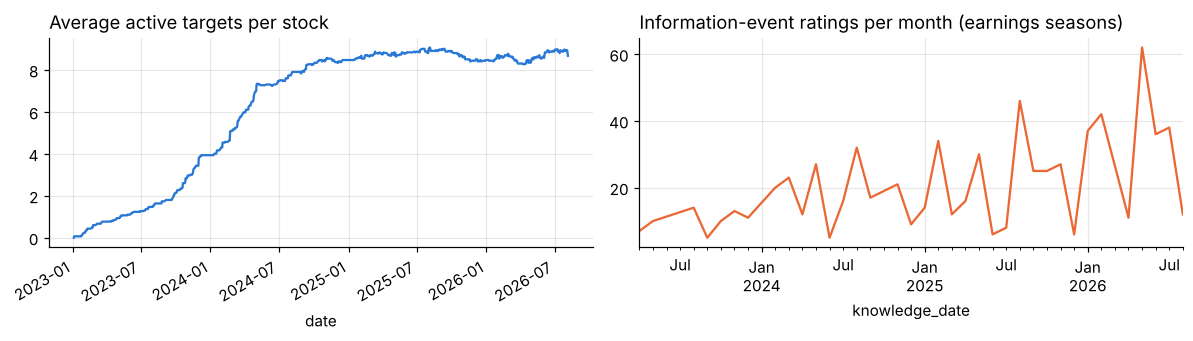

In [6]:
rt = out.ratings
print("knowledge date strictly after publication:", bool((rt["knowledge_date"] > rt["pub_date"]).all()))
lag = (rt["knowledge_date"] - rt["pub_date"]).dt.days
print("calendar days from publication to usability:", lag.describe()[["min", "50%", "max"]].to_dict())
snap = out.snapshot
ev = snap.events
print(ev["kind"].value_counts(normalize=True).round(3).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
snap.n_active.mean(axis=1).plot(ax=ax[0], color=BLUE); ax[0].set_title("Average active targets per stock", loc="left")
_e = ev[ev["event_day"]]; _e.groupby(_e["knowledge_date"].dt.to_period("M")).size().plot(ax=ax[1], color=ORANGE)
ax[1].set_title("Information-event ratings per month (earnings seasons)", loc="left"); plt.tight_layout(); plt.show()

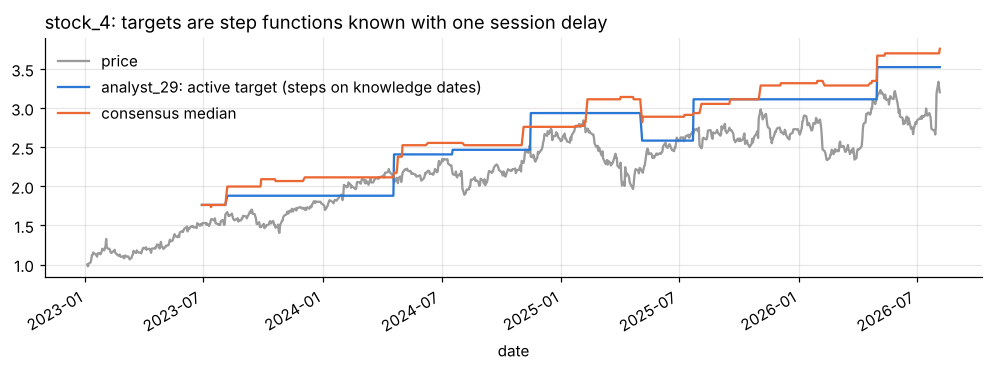

In [7]:
# One stock, one analyst: the active target, its age, and the consensus
s = snap.n_active.mean().idxmax()
a = ev[ev["stock"] == s]["analyst"].value_counts().index[0]
fig, ax = plt.subplots(figsize=(11, 3.2))
(out.prices[s]).plot(ax=ax, color=GREY, label="price")
snap.tp[(s, a)].plot(ax=ax, color=BLUE, label=f"{a}: active target (steps on knowledge dates)")
snap.cons_median[s].plot(ax=ax, color=ORANGE, label="consensus median")
ax.legend(frameon=False); ax.set_title(f"{s}: targets are step functions known with one session delay", loc="left"); plt.show()

## 5. Causality audit for *your* configuration

`truncation_check` reruns the pipeline on data truncated at each cut date T and requires every signal, the composite and the weights to be identical to the full run up to T. Any difference is look-ahead. Run it every time you add a signal or change a data rule.

In [8]:
from fmflow.robustness import truncation_check
tc = truncation_check(P, R, CFG.with_(allocator="EW"), ["2024-06-28", "2025-06-30"])
display(tc.groupby("object")["causal"].all().to_frame().T)
assert tc["causal"].all()

object,composite,signal:breadth_63,signal:breadth_resid_mom,signal:event_breadth_63,signal:herders_only,signal:leader_minus_herd,signal:leaders_only,weights
causal,True,True,True,True,True,True,True,True
